# 📊 Exploratory Data Analysis — Applicant Profiles

This notebook performs EDA on `data/applicants.csv` (400 synthetic entrepreneur profiles) 
to understand distributions, categorical breakdowns, and potential natural groupings 
before we build the SchemeMatch model.

---
## 1. Setup & Imports

In [1]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Plot styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 100          # screen display
SAVE_DPI = 150                             # saved file resolution

# Output folder for saved visualizations
VIZ_DIR = os.path.join("..", "visualizations")
os.makedirs(VIZ_DIR, exist_ok=True)

print("Setup complete.")

Setup complete.


---
## 2. Data Loading & Basic Inspection

In [2]:
# Load the applicant dataset
df = pd.read_csv(os.path.join("..", "data", "applicants.csv"))

# Shape of the dataset
print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")

Dataset shape: 400 rows × 9 columns


In [3]:
# Column data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   applicant_id         400 non-null    str  
 1   age                  400 non-null    int64
 2   annual_income        400 non-null    int64
 3   sector               400 non-null    str  
 4   business_stage       400 non-null    str  
 5   location             400 non-null    str  
 6   social_category      400 non-null    str  
 7   funding_requirement  400 non-null    int64
 8   purpose              400 non-null    str  
dtypes: int64(3), str(6)
memory usage: 47.4 KB


In [4]:
# Check for missing values in each column
missing = df.isnull().sum()
print("Missing values per column:")
print(missing)
print(f"\nTotal missing values: {missing.sum()}")

Missing values per column:
applicant_id           0
age                    0
annual_income          0
sector                 0
business_stage         0
location               0
social_category        0
funding_requirement    0
purpose                0
dtype: int64

Total missing values: 0


In [5]:
# Check for duplicate rows
dup_count = df.duplicated().sum()
print(f"Duplicate rows: {dup_count}")

Duplicate rows: 0


In [6]:
# Summary statistics for numerical columns
df.describe()

,age,annual_income,funding_requirement
count,400.000000,4.000000e+02,4.000000e+02
mean,30.867500,3.042750e+05,7.480000e+05
std,8.157592,2.128341e+05,1.052761e+06
min,16.000000,5.000000e+04,2.000000e+04
25%,24.000000,1.400000e+05,2.000000e+05
50%,31.000000,2.400000e+05,3.500000e+05
75%,36.000000,4.150000e+05,6.100000e+05
max,58.000000,1.135000e+06,6.030000e+06


---
## 3. Categorical Feature Breakdown

In [7]:
# List of categorical columns to inspect
cat_cols = ["sector", "business_stage", "location", "social_category", "purpose"]

for col in cat_cols:
    print(f"\n{'='*40}")
    print(f"  {col.upper()}  ({df[col].nunique()} unique values)")
    print(f"{'='*40}")
    counts = df[col].value_counts()
    # Show count and percentage side by side
    for val, cnt in counts.items():
        pct = cnt / len(df) * 100
        print(f"  {val:<25s} {cnt:>4d}  ({pct:5.1f}%)")


  SECTOR  (5 unique values)
  Manufacturing               91  ( 22.8%)
  Food Processing             81  ( 20.2%)
  Agri-Allied                 81  ( 20.2%)
  Trading                     77  ( 19.2%)
  Service                     70  ( 17.5%)

  BUSINESS_STAGE  (3 unique values)
  Existing                   186  ( 46.5%)
  New                        182  ( 45.5%)
  Planning                    32  (  8.0%)

  LOCATION  (2 unique values)
  Rural                      214  ( 53.5%)
  Urban                      186  ( 46.5%)

  SOCIAL_CATEGORY  (6 unique values)
  Women                       96  ( 24.0%)
  General                     83  ( 20.8%)
  OBC                         71  ( 17.8%)
  SC                          61  ( 15.2%)
  Minority                    45  ( 11.2%)
  ST                          44  ( 11.0%)

  PURPOSE  (5 unique values)
  Machinery & Equipment      111  ( 27.8%)
  Working Capital             81  ( 20.2%)
  Unit Setup                  75  ( 18.8%)
  Business Expansi

---
## 4. Visualizations

### 4.1 Numerical Distributions

Histograms with KDE curves for `age`, `annual_income`, and `funding_requirement`.

C:\Users\Ritu Raj\AppData\Local\Temp\ipykernel_25876\1630128452.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels([f"{int(t/100000)}L" if t >= 100000 else f"{int(t/1000)}K"
C:\Users\Ritu Raj\AppData\Local\Temp\ipykernel_25876\1630128452.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[2].set_xticklabels([f"{int(t/100000)}L" if t >= 100000 else f"{int(t/1000)}K"


Saved → ..\visualizations\eda_numerical_distributions.png


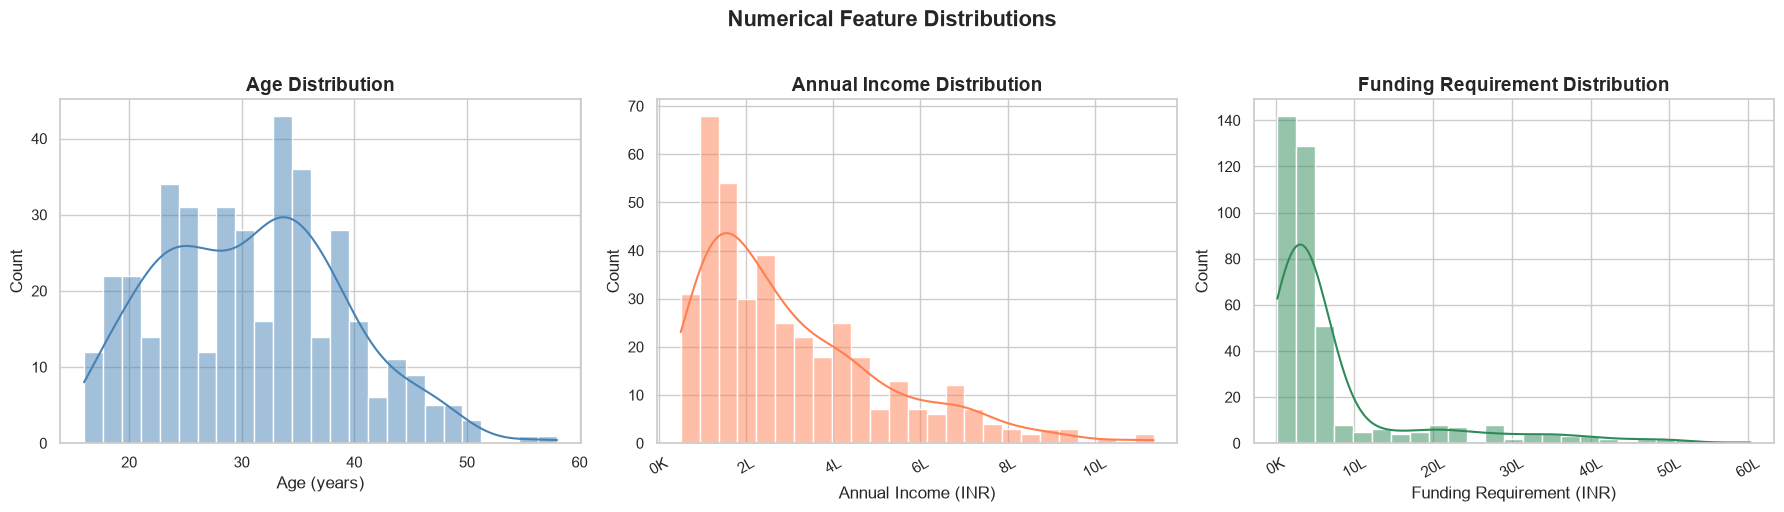

In [8]:
# Create a 1x3 figure for numerical distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- Age distribution ---
sns.histplot(df["age"], bins=25, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Age Distribution", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Count")

# --- Annual Income distribution ---
sns.histplot(df["annual_income"], bins=25, kde=True, color="coral", ax=axes[1])
axes[1].set_title("Annual Income Distribution", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Annual Income (INR)")
axes[1].set_ylabel("Count")
# Format x-axis labels for readability (in lakhs)
axes[1].ticklabel_format(style="plain", axis="x")
axes[1].set_xticklabels([f"{int(t/100000)}L" if t >= 100000 else f"{int(t/1000)}K"
                         for t in axes[1].get_xticks()], rotation=30)

# --- Funding Requirement distribution ---
sns.histplot(df["funding_requirement"], bins=25, kde=True, color="seagreen", ax=axes[2])
axes[2].set_title("Funding Requirement Distribution", fontsize=14, fontweight="bold")
axes[2].set_xlabel("Funding Requirement (INR)")
axes[2].set_ylabel("Count")
axes[2].ticklabel_format(style="plain", axis="x")
axes[2].set_xticklabels([f"{int(t/100000)}L" if t >= 100000 else f"{int(t/1000)}K"
                         for t in axes[2].get_xticks()], rotation=30)

fig.suptitle("Numerical Feature Distributions", fontsize=16, fontweight="bold", y=1.02)
fig.tight_layout()

# Save the figure
save_path = os.path.join(VIZ_DIR, "eda_numerical_distributions.png")
fig.savefig(save_path, dpi=SAVE_DPI, bbox_inches="tight")
print(f"Saved → {save_path}")
plt.show()

### 4.2 Categorical Counts

Bar charts for `sector`, `business_stage`, `location`, and `social_category`.

Saved → ..\visualizations\eda_categorical_counts.png


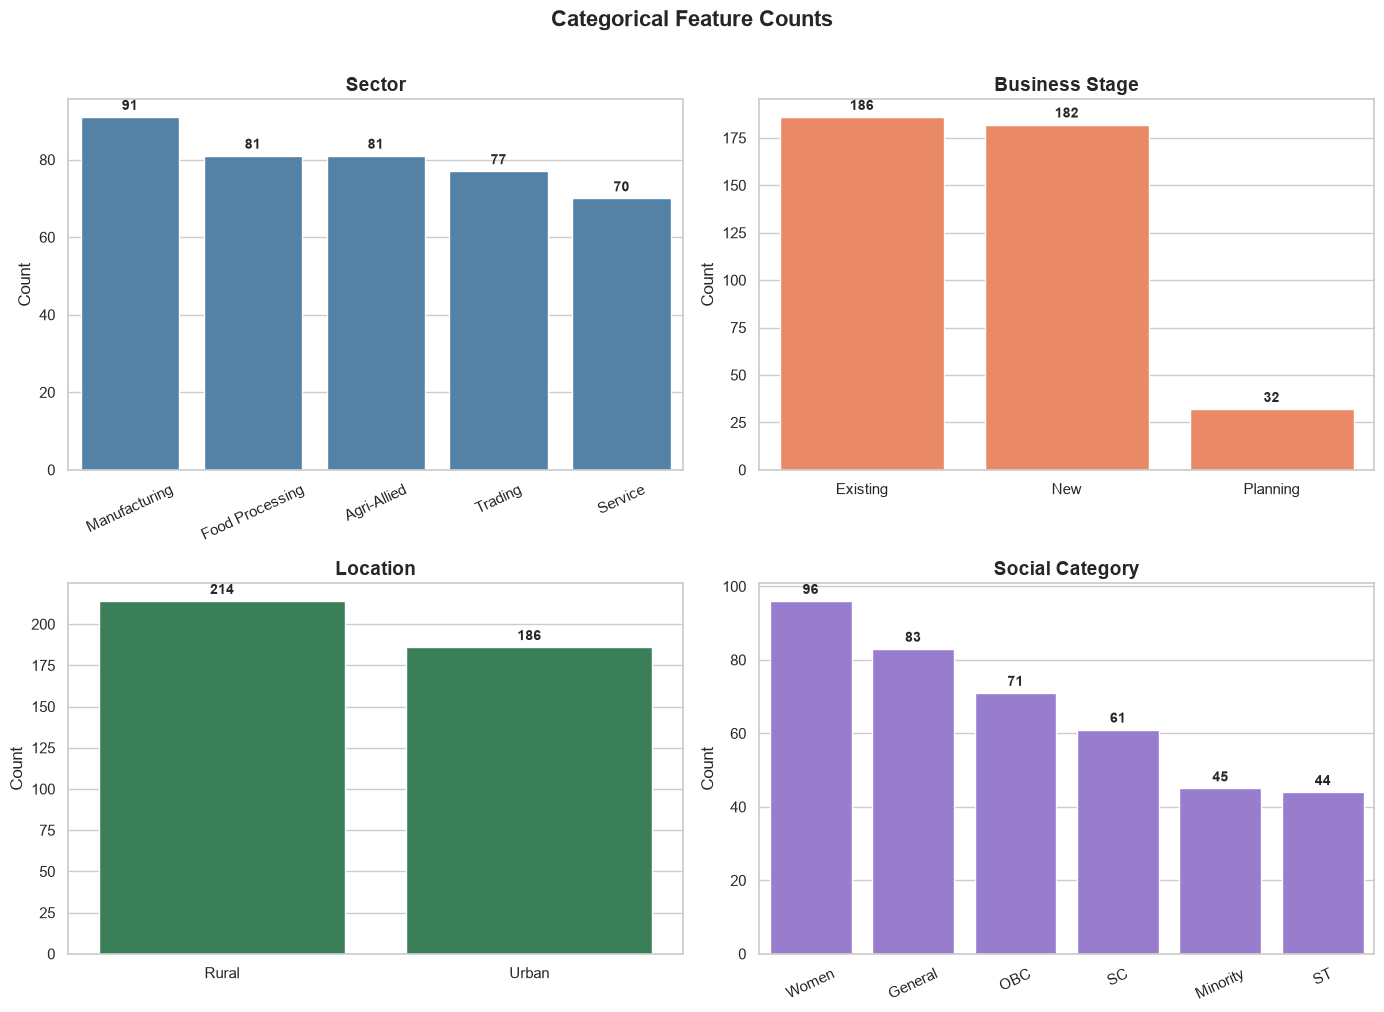

In [9]:
# Create a 2x2 figure for categorical bar charts
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

cat_plot_cols = ["sector", "business_stage", "location", "social_category"]
colors = ["steelblue", "coral", "seagreen", "mediumpurple"]

for ax, col, color in zip(axes.flatten(), cat_plot_cols, colors):
    # Get value counts sorted by count (descending)
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, color=color, ax=ax)
    
    # Add count labels on top of each bar
    for container in ax.containers:
        ax.bar_label(container, fontsize=10, fontweight="bold", padding=3)
    
    ax.set_title(col.replace("_", " ").title(), fontsize=14, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    # Rotate labels if many categories
    if len(order) > 3:
        ax.tick_params(axis="x", rotation=25)

fig.suptitle("Categorical Feature Counts", fontsize=16, fontweight="bold", y=1.01)
fig.tight_layout()

# Save the figure
save_path = os.path.join(VIZ_DIR, "eda_categorical_counts.png")
fig.savefig(save_path, dpi=SAVE_DPI, bbox_inches="tight")
print(f"Saved → {save_path}")
plt.show()

### 4.3 Income vs Funding (by Sector)

Scatter plot to visually inspect potential natural groupings among applicants.

Saved → ..\visualizations\eda_income_vs_funding.png


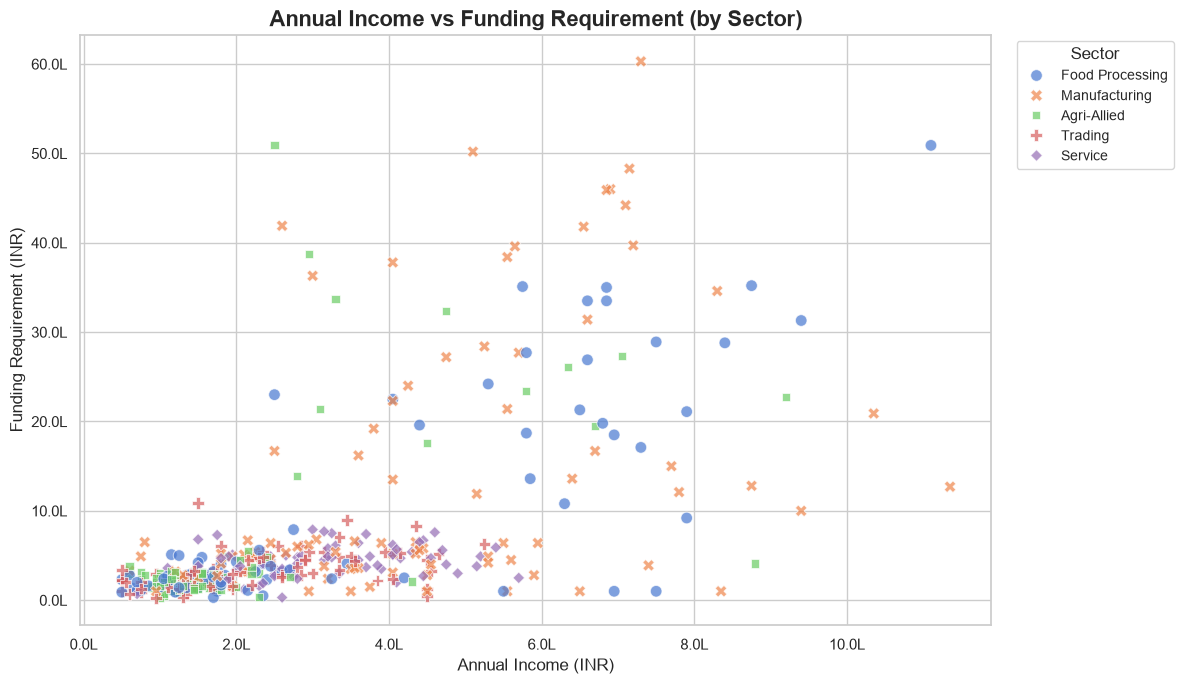

In [10]:
# Scatter plot: annual_income vs funding_requirement, colored by sector
fig, ax = plt.subplots(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="annual_income",
    y="funding_requirement",
    hue="sector",
    style="sector",
    s=70,
    alpha=0.7,
    ax=ax
)

ax.set_title("Annual Income vs Funding Requirement (by Sector)",
             fontsize=16, fontweight="bold")
ax.set_xlabel("Annual Income (INR)", fontsize=12)
ax.set_ylabel("Funding Requirement (INR)", fontsize=12)

# Format tick labels for readability
ax.ticklabel_format(style="plain", axis="both")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/100000:.1f}L"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/100000:.1f}L"))

# Move legend outside the plot
ax.legend(title="Sector", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=10)

fig.tight_layout()

# Save the figure
save_path = os.path.join(VIZ_DIR, "eda_income_vs_funding.png")
fig.savefig(save_path, dpi=SAVE_DPI, bbox_inches="tight")
print(f"Saved → {save_path}")
plt.show()

---
## 5. Key Observations

*(To be filled in after reviewing the charts above.)*

- **Age**: …
- **Income**: …
- **Funding**: …
- **Sector mix**: …
- **Scatter pattern**: …